# PD-модель для повторных заёмщиков: GRU-признак из сырой истории + отбор признаков + XGBoost

**Задача.** Оценить вероятность дефолта по заявке повторного клиента кредитора коротких займов.
Целевая переменная — **NPL30d90**: просрочка 30+ дней в первые 90 дней жизни займа. Сегменты: **L2 / L3 / L4+** — 2-й, 3-й, 4-й и последующие займы клиента.

**Решение из трёх блоков**
1. **GRU реконструирует признак из сырой последовательности событий клиента**: выдачи, платежи, пролонгации, закрытия, автосписания. Агрегаты фабрики признаков теряют порядок и микродинамику событий. Рекуррентная сеть возвращает эту информацию одним числом — `gru_score`, out-of-fold логитом.
2. **Отбор признаков** из 300+ кандидатов: технические фильтры → утечки → стабильность (PSI) → IV на valid → значимость из бустинга (gain / SHAP / permutation) против шумовых «канареек» → MRMR → ансамбль рангов → корреляции → кривая насыщения.
3. **XGBoost** на отобранных признаках + `gru_score` (стекинг). Гиперпараметры подбирает Optuna, целевая метрика — *penalized valid Gini* со штрафом за переобучение. Модель сравнивается с бустингом без GRU, с одиночным GRU и с классической WoE-скоркартой; доверительные интервалы — бутстрэп по клиентам.

**Данные синтетические.** Генератор (`src/scoring/synth.py`) моделирует скрытый риск клиента, его динамику и поток событий в том виде, в каком его хранит DWH кредитора. Поэтому проект можно выложить публично, а реалистичные эффекты сохраняются: дрейф признаков, утечка, пустые и константные поля, мультиколлинеарность, рост уровня дефолта в OOT.

| Раздел | Содержание |
|---|---|
| 1. Данные | объёмы, уровень дефолта, поток событий, история клиента, каталог признаков |
| 2. Разбиение и PIT | train / valid по клиентам, OOT по времени, проверка point-in-time |
| 3. GRU | токены, архитектура, OOF по клиентам, качество `gru_score` |
| 4. Отбор признаков | воронка 300+ → финальный набор |
| 5. XGBoost | Optuna, финальные модели, WoE-скоркарта как бейзлайн |
| 6. Сравнение | Gini, KS, бутстрэп ΔGini, сегменты, ROC |
| 7. Интерпретация | SHAP |
| 8. Стабильность и калибровка | помесячный Gini, PSI, калибровка, риск-грейды |
| 9. Бизнес-эффект | стратегическая кривая «уровень одобрения → риск» |
| 10. Внедрение | инференс GRU на numpy, паритет с torch, артефакты |
| 11. Выводы | |

In [1]:
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*IProgress not found.*")   # optuna -> tqdm in a headless kernel

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import xgboost as xgb
from IPython.display import Markdown, display

from scoring import features as fe, gru as G, metrics as mt, modeling as md, plots as pl, selection as sel, sequences as sq, synth
from scoring.config import ARTEFACTS_DIR, AUX_TARGETS, DATA_DIR, FIGURES_DIR, OOT_START, SEED, TARGET

pl.setup_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.4f}".format)

FIG = FIGURES_DIR          # все графики дублируются в reports/figures для README
N_JOBS = 8
N_TRIALS = 40              # Optuna, на каждую модель
GRU_CFG = G.GRUConfig(epochs=10, patience=2, threads=N_JOBS)
T_START = time.time()

## 1. Данные

Источники — как в DWH кредитора:
- `applications` — повторные заявки с выдачей и таргетами (NPL30d90, FPD10/15/30);
- `loans` — договоры: сумма, срок, дата выдачи, плановая дата;
- `events` — сырой поток событий по займам: выдача, платёж (с разбивкой на основной долг, проценты и пени), пролонгация, закрытие, отмена платежа, неуспешное автосписание;
- `external_features` — снимки на момент заявки: кредитное бюро, анкета, цифровой след.

Если данных ещё нет, ячейка ниже сгенерирует их (≈10 секунд). То же делает `python scripts/generate_data.py`.

In [2]:
t0 = time.time()
if not (DATA_DIR / "features.parquet").exists():
    _d = synth.generate(synth.SynthConfig())
    synth.save(_d, DATA_DIR)
    fe.build_features(_d.applications, _d.loans, _d.events, _d.external).to_parquet(DATA_DIR / "features.parquet", index=False)
data = synth.load(DATA_DIR)
apps, loans, events = data.applications, data.loans, data.events
feats = pd.read_parquet(DATA_DIR / "features.parquet")
print(f"Заявок: {len(apps):,} | клиентов: {apps.client_id.nunique():,} | займов в истории: {len(loans):,} | "
      f"событий: {len(events):,} | признаков: {feats.shape[1] - 1} ({time.time() - t0:.0f} c)")
display(events.head(8))

Заявок: 57,657 | клиентов: 23,389 | займов в истории: 119,923 | событий: 680,872 | признаков: 304 (10 c)


,client_id,loan_id,event_time,event,amount,amt_main,amt_percent,amt_penalty,category,plan_end_after
0,1,1,2024-10-11 08:12:00,issue,0.0000,0.0000,0.0000,0.0000,,2024-10-25 12:00:00
1,1,1,2024-10-25 08:19:00,autodebit_fail,0.0000,0.0000,0.0000,0.0000,recurrent,NaT
2,1,1,2024-10-26 08:18:00,autodebit_fail,0.0000,0.0000,0.0000,0.0000,recurrent,NaT
3,1,1,2024-10-27 08:54:00,autodebit_fail,0.0000,0.0000,0.0000,0.0000,recurrent,NaT
4,1,1,2024-11-03 11:26:00,payment,5965.0000,5000.0000,920.0000,45.0000,loan,NaT
5,1,1,2024-11-03 11:26:00,closure,0.0000,0.0000,0.0000,0.0000,,NaT
6,1,45001,2024-11-12 21:25:00,issue,0.0000,0.0000,0.0000,0.0000,,2024-11-19 12:00:00
7,1,45001,2024-11-16 10:57:00,payment,2580.0000,2500.0000,80.0000,0.0000,loan,NaT


заявок  клиентов  npl30d90  fpd30  fpd10
period           segment                                          
OOT: 2026-01…04  L2         5905      5905    0.1865 0.1734 0.3409
                 L3         3819      3819    0.1767 0.1623 0.3168
                 L4+        7059      4173    0.1547 0.1415 0.2690
разработка: 2025 L2        14878     14878    0.1664 0.1539 0.3058
                 L3         9474      9474    0.1579 0.1460 0.2876
                 L4+       16522      6950    0.1329 0.1204 0.2436

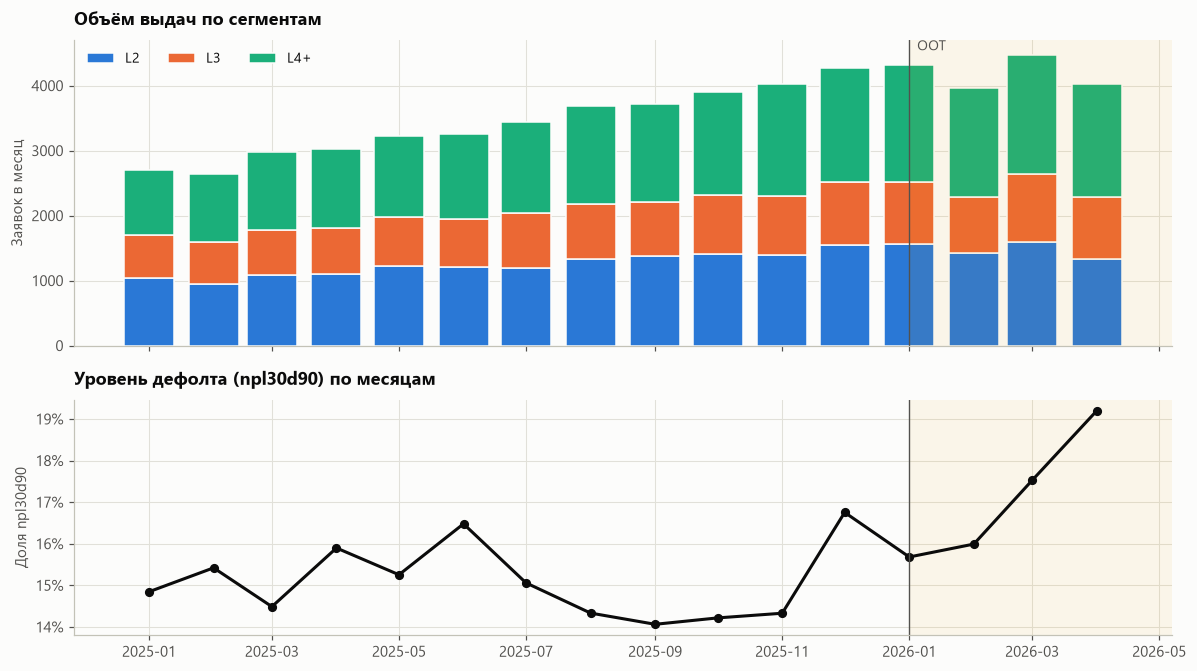

In [3]:
overview = (apps.assign(period=np.where(apps.is_oot.eq(1), "OOT: 2026-01…04", "разработка: 2025"))
            .groupby(["period", "segment"])
            .agg(заявок=("application_id", "size"), клиентов=("client_id", "nunique"),
                 npl30d90=(TARGET, "mean"), fpd30=("fpd30", "mean"), fpd10=("fpd10", "mean")))
display(overview)
pl.monthly_overview(apps, TARGET, OOT_START, FIG)
plt.show()

Уровень дефолта в OOT выше, чем в 2025 году: в генератор заложен макросдвиг с осени 2025-го. Так бывает и на реальных данных, и ниже это проявится в калибровке (раздел 8): ранжирование держится, а уровень PD нужно перекалибровывать.

**Как выглядит сырая история.** Ниже — займы и события одного клиента до момента скоринга заявки. Полосы — займы, вертикальный штрих — плановая дата погашения. Именно такую последовательность получает GRU.

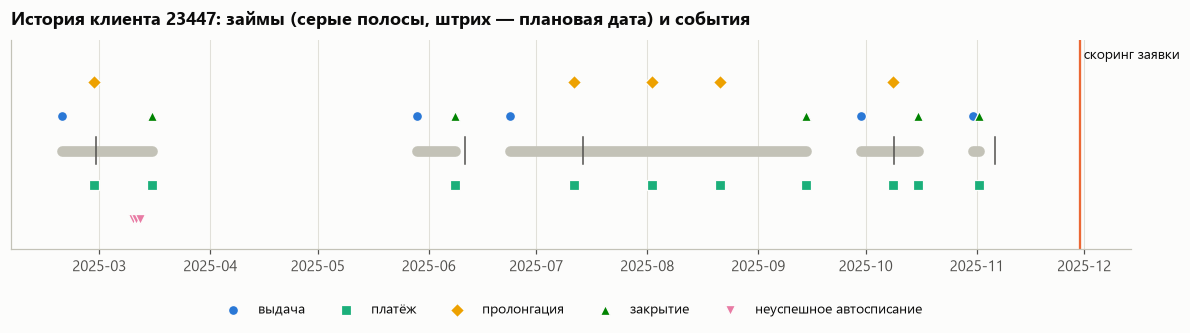

In [4]:
adf = set(events.loc[events.event.eq("autodebit_fail"), "client_id"])
prl = set(events.loc[events.event.eq("prolongation"), "client_id"])
cand = apps[apps.loan_no.between(5, 6) & apps.client_id.isin(adf & prl)]
ex = cand.sample(1, random_state=7).iloc[0]
hist_ev = events[(events.client_id == ex.client_id) & (events.event_time < ex.application_date)]
pl.client_timeline(hist_ev, loans[loans.loan_id.isin(hist_ev.loan_id)], ex.client_id, ex.application_date, FIG)
plt.show()

**Каталог признаков.** Фабрика считает агрегаты по прошлым займам и платежам клиента в окнах 30 / 60 / 90 / 180 / 365 дней и по всей истории: просрочки, пролонгации, досрочные погашения, частичные платежи, пени, тренды, взвешенные по давности средние, паузы между займами. К ним добавляются бюро, анкета и цифровой след. Всё считается строго на момент заявки.

In [5]:
FEATURES = [c for c in feats.columns if c != "application_id"]
catalog = fe.feature_catalog(FEATURES)
display(catalog.groupby(["group", "group_name"]).size().rename("признаков").reset_index())
display(catalog.groupby("group").head(3)[["group", "feature"]].reset_index(drop=True))

,group,group_name,признаков
0,app,Анкета и параметры заявки,31
1,bki,Кредитное бюро,44
2,coll,Взыскание,1
3,dig,Цифровой след,35
4,hist,Внутренняя кредитная история,193


,group,feature
0,hist,hist_loans_cnt_30d
1,hist,hist_amount_sum_30d
2,hist,hist_amount_mean_30d
3,app,app_loan_number
4,app,app_requested_amount
5,app,app_requested_term
6,bki,bki_inq_7d
7,bki,bki_inq_30d
8,bki,bki_inq_90d
9,dig,dig_form_fill_time_sec


## 2. Разбиение выборки и point-in-time

- **OOT** — заявки 2026-01…04. Это честный holdout: он не участвует ни в отборе признаков, ни в подборе гиперпараметров.
- **train / valid** — заявки 2025 года, разбитые **по клиентам**: 20% клиентов целиком уходят в valid. При случайном разбиении по заявкам одни и те же клиенты попадают в обе части, и valid начинает поощрять модели, которые запоминают людей. Особенно этим грешат нейросети.
- Фолды OOF для GRU тоже строятся по клиентам.

In [6]:
df = apps.merge(feats, on="application_id", validate="one_to_one")
is_oot = df.is_oot.eq(1).to_numpy()
fold = np.full(len(df), -1)
fold[~is_oot] = G.client_folds(df.client_id.to_numpy()[~is_oot], 5, SEED)
df["split"] = np.where(is_oot, "oot", np.where(fold == 0, "valid", "train"))
assert not set(df.loc[df.split.eq("train"), "client_id"]) & set(df.loc[df.split.eq("valid"), "client_id"])
display(df.groupby("split").agg(заявок=("application_id", "size"), клиентов=("client_id", "nunique"),
                                с=("application_date", "min"), по=("application_date", "max"), npl30d90=(TARGET, "mean"))
          .loc[["train", "valid", "oot"]])

,заявок,клиентов,с,по,npl30d90
split,,,,,
train,32518,13984,2025-01-01 00:45:00,2025-12-31 21:36:00,0.1518
valid,8356,3496,2025-01-01 04:59:00,2025-12-31 23:35:00,0.1473
oot,16783,10110,2026-01-01 00:36:00,2026-04-29 23:39:00,0.1709


**Проверка point-in-time.** Для случайных 300 заявок признаки истории пересчитываются заново на событиях, обрезанных моментом заявки, и сравниваются с массовым расчётом. Если бы массовый расчёт использовал хоть что-то из будущего или перепутал строки между заявками, значения бы разошлись.

> При разработке эта проверка поймала реальную ошибку: recency-признаки присваивались массивом без выравнивания по индексу и «съезжали» между заявками. После исправления расхождений нет.

In [7]:
ids = df.sample(300, random_state=SEED).application_id.tolist()
recomputed = fe.pit_recompute(ids, apps, loans, events).set_index("application_id")
batch = feats.set_index("application_id").loc[ids, recomputed.columns]
mismatch = ((recomputed - batch).abs() > 1e-9) & ~(recomputed.isna() & batch.isna())
print(f"Пересчитано: {len(ids)} заявок × {recomputed.shape[1]} признаков истории. Расхождений: {int(mismatch.values.sum())}")
assert mismatch.values.sum() == 0

Пересчитано: 300 заявок × 199 признаков истории. Расхождений: 0


## 3. GRU: реконструкция признака из последовательности событий

**Токен** — всё, что произошло с одним займом за одну минуту (например, платёж и закрытие). Поля токена считаются только по информации, известной на момент токена (29 полей):

| Группа | Поля |
|---|---|
| договор | `log_loan_sum`, `log_loan_term`, `loan_no` |
| состояние займа | `loan_age`, `dpd_at_token`, `days_to_due_after`, `ext_days`, `late_vs_first_plan`, `principal_left_ratio`, `paid_ratio`, `n_prol` |
| портфель клиента | `open_loans`, `dt_prev` |
| календарь | `dow_sin/cos`, `hour_sin/cos` |
| суммы платежа | `amt_main`, `amt_percent`, `amt_penalty` (в % от суммы займа, signed log) |
| тип события | `ev_issue`, `ev_payment`, `ev_prolongation`, `ev_closure`, `ev_cancel`, `ev_autodebit_fail`, `cat_loan`, `cat_prolongation`, `cat_recurrent` |

Давность токена относительно заявки добавляется на лету при сборке батча. Берутся последние 128 токенов строго до заявки.

**Модель:**
```
token → Linear(29+1 → 64) + GELU → GRU(64) → h_last
[h_last, segment embedding, has_history] → MLP(64) → логиты NPL30d90 + FPD30 / FPD15 / FPD10 (вес 0.3)
```
Вспомогательные головы FPD — multi-task-регуляризация энкодера: первый платёж наступает раньше NPL и даёт более плотный сигнал.

**Out-of-fold по клиентам.** Пул train+valid делится на 4 фолда по клиентам. `gru_score` для заявки из пула выдаёт модель фолда, которая этого клиента не видела. Early stopping идёт по ~15% обучающих клиентов фолда, а не по самому отложенному фолду. OOT получает среднее логитов четырёх моделей. Без OOF бустинг увидел бы на train «слишком хороший» GRU-скор и переоценил бы его — классическая утечка через стекинг.

Токенов: 541,467, полей: 29 (4 c). PIT по токенам: OK


,count,mean,std,min,50%,90%,99%,max
segment,,,,,,,,
L2,20783.0000,4.3616,2.2008,2.0000,4.0000,7.0000,10.0000,14.0000
L3,13293.0000,8.5179,3.3894,4.0000,8.0000,13.0000,17.0000,22.0000
L4+,23581.0000,18.5536,9.0742,6.0000,17.0000,31.0000,47.0000,77.0000


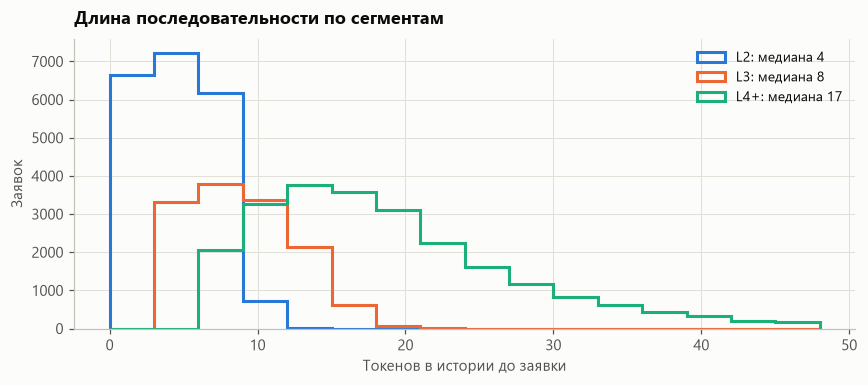

In [8]:
t0 = time.time()
meta, tokens = sq.build_tokens(events, loans)
store = sq.make_store(meta, tokens, df, OOT_START)
has = store.lengths > 0
assert (store.t[store.seq_end[has] - 1] < store.app_t[has]).all(), "PIT: токен позже заявки"
print(f"Токенов: {len(tokens):,}, полей: {tokens.shape[1]} ({time.time() - t0:.0f} c). PIT по токенам: OK")
display(df.assign(seq_len=store.lengths).groupby("segment").seq_len.describe(percentiles=[0.5, 0.9, 0.99]))
pl.sequence_lengths(store.lengths, df.segment.to_numpy(), FIG)
plt.show()

fold 1/4


  epoch 1: loss=0.6548 valid_gini=0.0376 (4s)


  epoch 2: loss=0.4575 valid_gini=0.4261 (4s)


  epoch 3: loss=0.4209 valid_gini=0.4630 (4s)


  epoch 4: loss=0.4168 valid_gini=0.4747 (4s)


  epoch 5: loss=0.4137 valid_gini=0.4839 (4s)


... (32 outputs left out)

  epoch 7: loss=0.4122 valid_gini=0.4986 (3s)


  epoch 8: loss=0.4110 valid_gini=0.4963 (4s)


  epoch 9: loss=0.4105 valid_gini=0.4959 (4s)


OOF GRU: 146 c


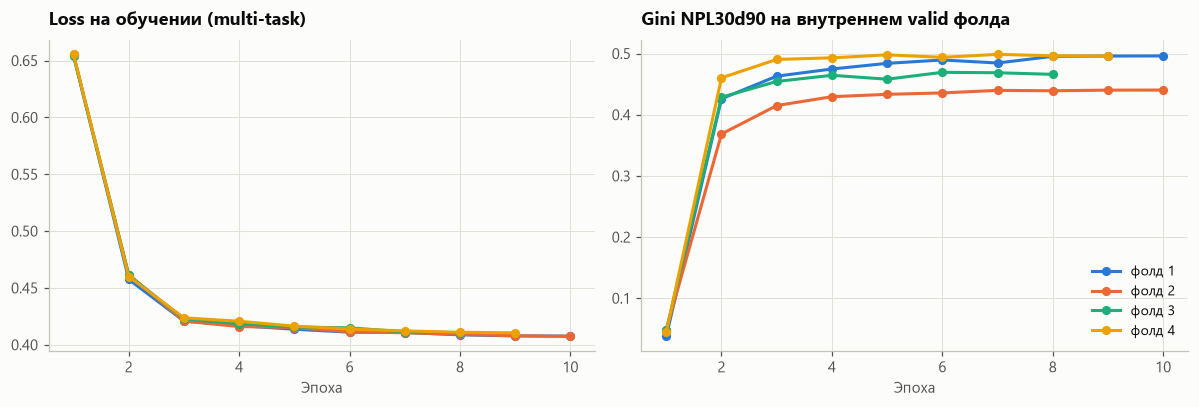

In [9]:
seg_idx = df.segment.map(G.SEGMENT_INDEX).to_numpy()
Y = df[[TARGET] + AUX_TARGETS].to_numpy(float)
pool = df.split.isin(["train", "valid"]).to_numpy()
t0 = time.time()
oof = G.fit_oof(store, seg_idx, Y, df.client_id.to_numpy(), pool, GRU_CFG, n_folds=4)
df["gru_score"] = oof.score
print(f"OOF GRU: {time.time() - t0:.0f} c")
pl.gru_learning_curves(oof.histories, FIG)
plt.show()

Gini одиночного gru_score (OOF на train/valid, среднее фолдов на OOT):


,train,valid,oot
все,0.4737,0.4787,0.4669
L2,0.3959,0.4007,0.3849
L3,0.4570,0.4764,0.4595
L4+,0.5460,0.5392,0.5313


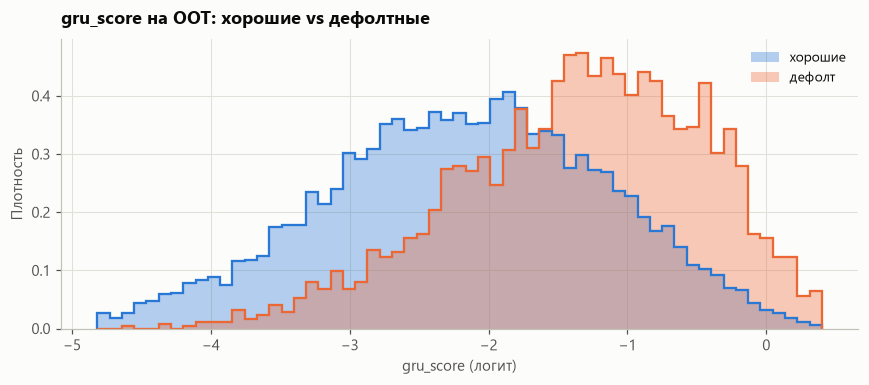

In [10]:
def gini_table(frame, score):
    out = {}
    for s in ["train", "valid", "oot"]:
        part = frame[frame.split.eq(s)]
        out[s] = {"все": mt.gini(part[TARGET], part[score]),
                  **{seg: mt.gini(g[TARGET], g[score]) for seg, g in part.groupby("segment")}}
    return pd.DataFrame(out)

print("Gini одиночного gru_score (OOF на train/valid, среднее фолдов на OOT):")
display(gini_table(df, "gru_score"))
o = df[df.split.eq("oot")]
pl.score_distribution(o.gru_score.to_numpy(), o[TARGET].to_numpy(), "gru_score на OOT: хорошие vs дефолтные",
                      "gru_score (логит)", FIG, "21_gru_score_distribution")
plt.show()

Одиночная GRU видит **только** историю событий — без бюро, анкеты и параметров текущей заявки — и всё равно уверенно ранжирует. Качество растёт с длиной истории: от L2 к L4+. Ценность GRU — не в качестве самом по себе, а в том, что она **дополняет** табличные признаки. Это проверяется ниже стекингом.

## 4. Отбор признаков: 300+ → финальный набор

Все шаги считаются на train и valid, OOT не используется.

| Шаг | Правило | Зачем |
|---|---|---|
| Технические фильтры | пропусков > 95%, одно значение > 99.5% строк | поля без информации |
| Утечки | univariate \|Gini\| WoE-признака на train > 0.5 | «слишком хорошо, чтобы быть правдой» → ручная проверка источника |
| Стабильность | max помесячный PSI к первым трём месяцам разработки > 0.25 | дрейф источника или смена методики расчёта |
| Сила признака | IV на valid < 0.02 (бины обучены деревом на train) | слабые признаки; IV на valid честнее, чем на train |
| Канарейки | признак не превосходит лучшую шумовую фичу ≥ 2 из 3 метрик (gain, SHAP, permutation) | отличаем сигнал от шума с учётом взаимодействий |
| MRMR + ансамбль рангов | сумма 1/rank по gain, SHAP, permutation, IV, MRMR | устойчивый порядок вместо одной метрики |
| Корреляции | \|ρ Спирмена\| ≥ 0.8 с уже выбранным | мультиколлинеарность |
| Кривая насыщения | минимальное число признаков в пределах 0.003 от лучшего Gini на кросс-валидации (3 фолда по клиентам на train+valid) | простая модель при том же качестве. Один valid слишком шумный: стандартная ошибка Gini ≈ 0.01 |

technical: 304 -> 296


leakage: -> 295  flagged: ['coll_calls_cnt_90d']


stability: -> 292  dropped: ['bki_score_v2', 'dig_app_version', 'dig_marketing_source']
iv: -> 219


canaries: -> 38


ensemble+corr: -> 21


saturation: best valid gini 0.5588, chosen n=20
Отбор: 158 c


,stage,n_features
0,Исходный набор,304
1,"Технические фильтры (пропуски, константы)",296
2,Подозрение на утечку (|Gini| > 0.5),295
3,Стабильность (PSI ≤ 0.25),292
4,Предсказательная сила (IV на valid ≥ 0.02),219
5,Важность выше шумовых канареек,38
6,Ансамбль рангов + корреляции (|ρ| < 0.8),21
7,Кривая насыщения (финальный набор),20


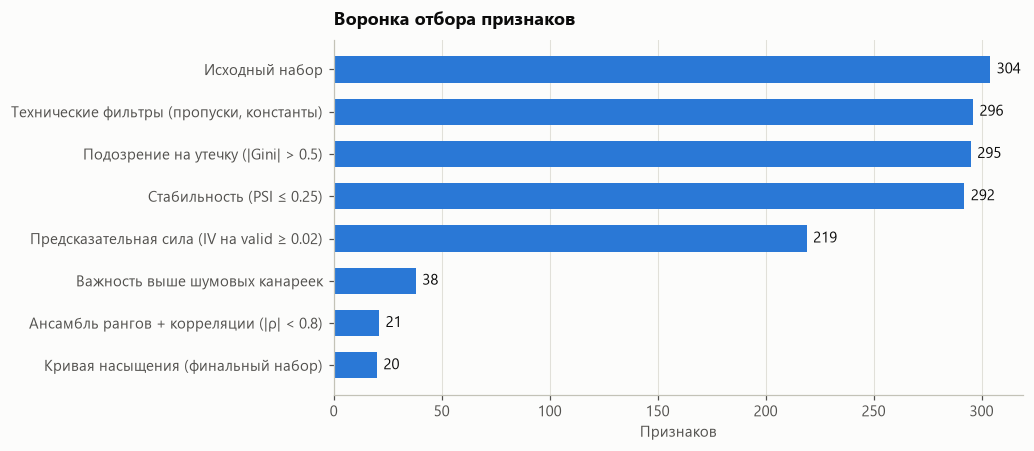

In [11]:
train, valid, test = (df[df.split.eq(s)].reset_index(drop=True) for s in ["train", "valid", "oot"])
t0 = time.time()
selres = sel.select_features(train, valid, FEATURES, TARGET, "application_date", sel.SelectionConfig(n_jobs=N_JOBS))
SELECTED, T = selres.selected, selres.tables
print(f"Отбор: {time.time() - t0:.0f} c")
display(selres.funnel)
pl.selection_funnel(selres.funnel, FIG)
plt.show()

In [12]:
print("Технические фильтры:")
display(T["technical"].query("drop_reason != ''").sort_values(["drop_reason", "feature"]))
print("Подозрение на утечку (топ по univariate Gini на train):")
display(T["leakage"].sort_values("train_gini", ascending=False).head(6))

Технические фильтры:


,feature,missing_share,n_unique,top_share,drop_reason
297,dig_help_page_views,0.0000,1,1.0000,constant
11,hist_dpd30_cnt_30d,0.0000,1,1.0000,constant
265,app_employer_inn_flag,0.9795,2,0.7650,missing
300,dig_selfie_quality,0.9560,1430,0.0007,missing
299,dig_social_score,0.9685,396,0.0088,missing
264,app_country_code,0.0000,2,0.9996,quasi_constant
282,dig_emulator_flag,0.0000,2,0.9991,quasi_constant
10,hist_dpd15_share_30d,0.6492,2,0.9953,quasi_constant


Подозрение на утечку (топ по univariate Gini на train):


,feature,train_gini,valid_gini,leak_flag
293,coll_calls_cnt_90d,0.9787,0.9791,True
223,bki_score,0.4404,0.4501,False
238,bki_score_v2,0.4250,0.4341,False
169,hist_tw_dpd_mean,0.3893,0.4141,False
164,hist_dpd_mean_last3,0.3843,0.4064,False
105,hist_dpd_mean_365d,0.3791,0.4047,False


`coll_calls_cnt_90d` — «звонки взыскания за 90 дней». Поле выглядит как обычная историческая фича, но в источнике окно отсчитывается от даты отчёта, а не от даты заявки. Поэтому оно захватывает звонки **после** выдачи скорингуемого займа. Univariate Gini около 0.98 при лучших честных признаках около 0.4 — сигнал проверить происхождение поля, а не радоваться.

Самые нестабильные признаки (PSI по месяцам разработки):


,feature,psi_max,psi_last,train_iv,valid_iv,n_bins
278,dig_app_version,15.8688,15.8115,0.0042,0.0046,8
238,bki_score_v2,7.8301,7.8301,0.6172,0.6447,9
279,dig_marketing_source,3.0319,2.8580,0.0022,0.0044,6
257,app_weekday,0.0304,0.0294,0.0020,0.0052,7
191,app_loan_number,0.0289,0.0247,0.0274,0.0303,6
123,hist_loans_cnt_all,0.0289,0.0247,0.0274,0.0303,6
178,hist_days_since_first_loan,0.0225,0.0153,0.0434,0.0615,8
98,hist_loans_cnt_365d,0.0211,0.0131,0.0469,0.0396,6
272,dig_page_views_cnt,0.0193,0.0085,0.0085,0.0310,8
102,hist_amount_min_365d,0.0169,0.0117,0.0286,0.0199,9


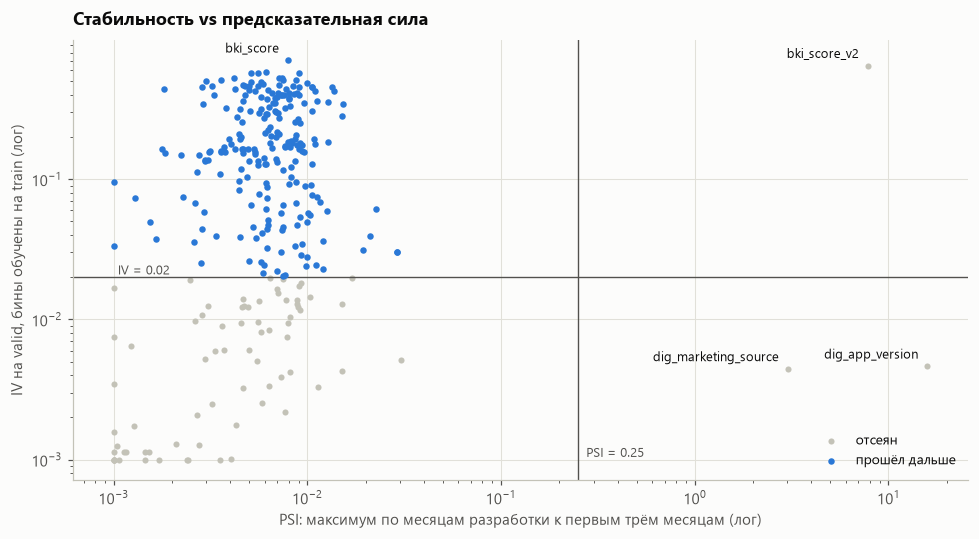

In [13]:
print("Самые нестабильные признаки (PSI по месяцам разработки):")
display(T["stability"].merge(T["iv"], on="feature").sort_values("psi_max", ascending=False).head(10))
traps = ["dig_app_version", "bki_score_v2", "dig_marketing_source"]
top_iv = T["iv"].sort_values("valid_iv", ascending=False).feature.head(1).tolist()
pl.iv_vs_psi(T["iv"], T["stability"], 0.02, 0.25, annotate=traps + top_iv, out_dir=FIG)
plt.show()

PSI ловит заложенные ловушки:
- `bki_score_v2` — бюро сменило шкалу скора в октябре 2025;
- `dig_app_version` — версия приложения растёт каждый месяц;
- `dig_marketing_source` — с ноября появился новый канал привлечения.

Такие признаки на OOT вели бы себя иначе, чем на обучении.

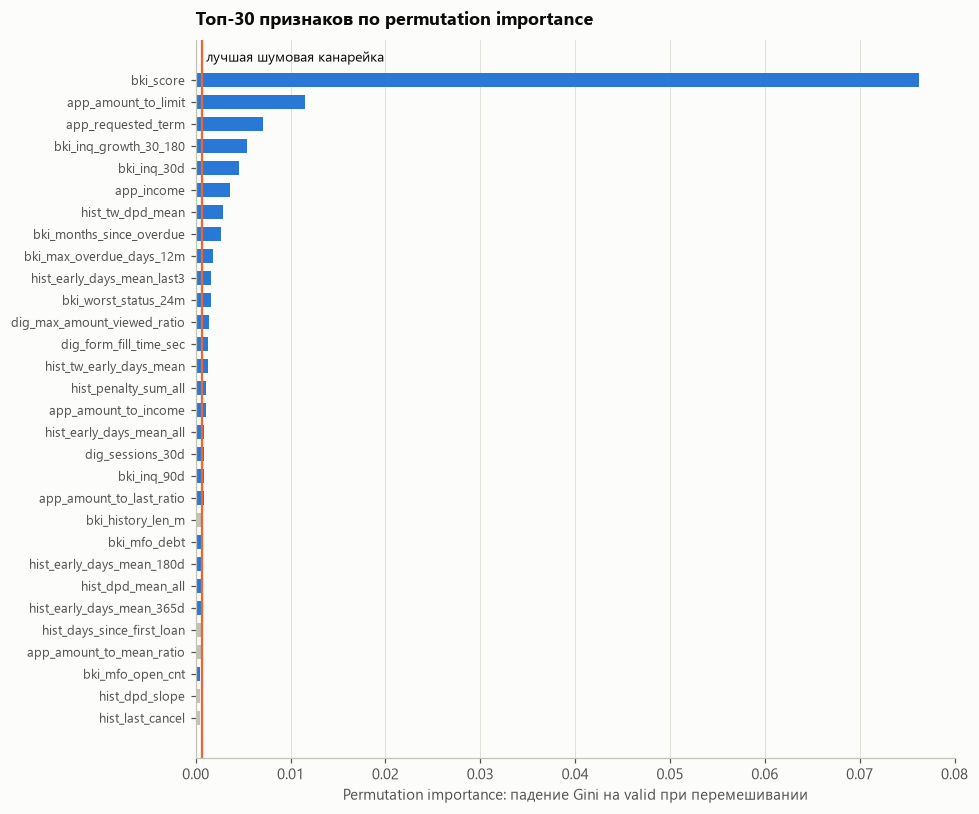

Порог шума (лучшая канарейка по каждой метрике):


,порог
gain_importance,0.0025
mean_abs_shap,0.0125
permutation_importance,0.0007


In [14]:
pl.evidence_vs_canaries(T["evidence"], T["canary_floor"], top=30, out_dir=FIG)
plt.show()
print("Порог шума (лучшая канарейка по каждой метрике):")
display(T["canary_floor"].to_frame("порог"))

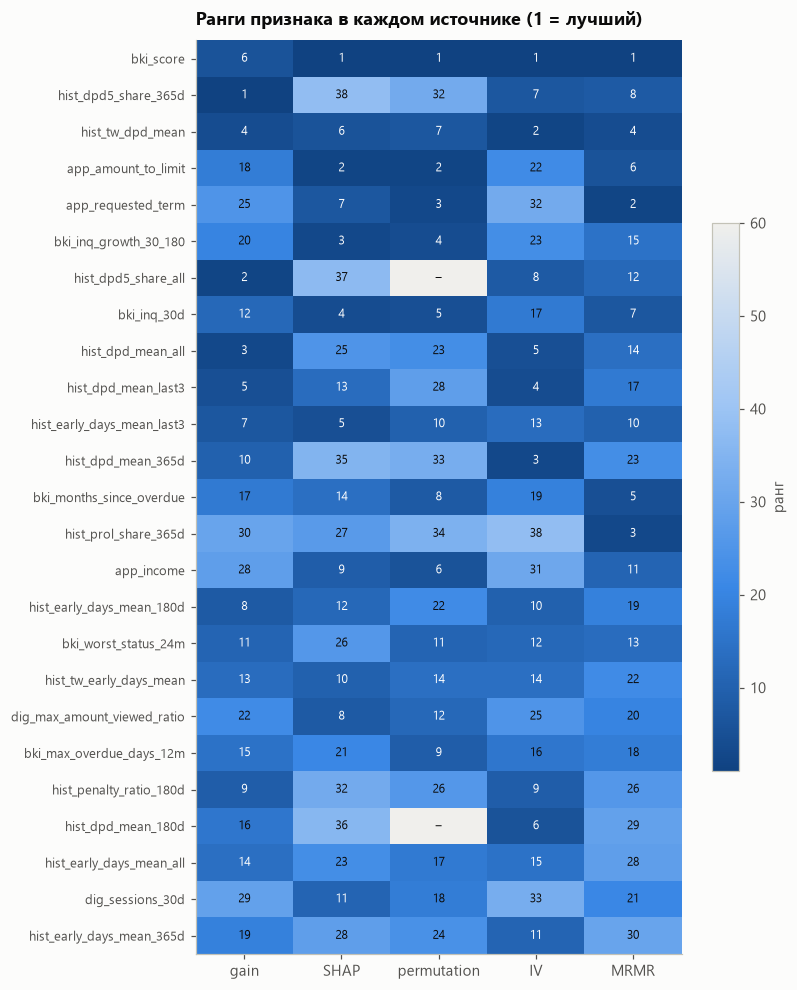

Отсеяны корреляцией с более сильным признаком:


,feature,max_corr_with_kept,most_correlated,kept
2,hist_tw_dpd_mean,0.9136,hist_dpd5_share_365d,False
6,hist_dpd5_share_all,0.9985,hist_dpd5_share_365d,False
7,bki_inq_30d,0.9133,bki_inq_growth_30_180,False
8,hist_dpd_mean_all,0.9150,hist_dpd5_share_365d,False
9,hist_dpd_mean_last3,0.8930,hist_dpd5_share_365d,False
11,hist_dpd_mean_365d,0.9165,hist_dpd5_share_365d,False
15,hist_early_days_mean_180d,0.9818,hist_early_days_mean_last3,False
17,hist_tw_early_days_mean,0.9851,hist_early_days_mean_last3,False
18,dig_max_amount_viewed_ratio,0.8931,app_amount_to_limit,False
19,bki_max_overdue_days_12m,0.8547,bki_worst_status_24m,False


In [15]:
pl.ensemble_heatmap(T["ensemble"], top=25, out_dir=FIG)
plt.show()
print("Отсеяны корреляцией с более сильным признаком:")
display(T["correlation"].query("~kept").head(10))

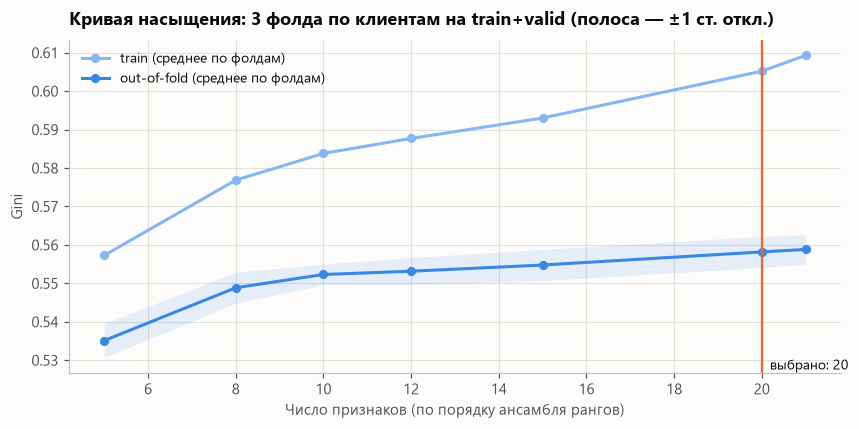

Финальный набор: 20 признаков


,feature,источник,train_iv,valid_iv,n_bins,psi_max,psi_last,ensemble_score,top_sources
0,bki_score,Кредитное бюро,0.6737,0.7044,9,0.0080,0.0036,4.1667,5
1,hist_dpd5_share_365d,Внутренняя кредитная история,0.4516,0.5122,6,0.0087,0.0030,1.3254,5
2,app_amount_to_limit,Анкета и параметры заявки,0.3312,0.2908,8,0.0062,0.0030,1.2677,5
3,app_requested_term,Анкета и параметры заявки,0.0383,0.0673,5,0.0026,0.0014,1.0474,5
4,bki_inq_growth_30_180,Кредитное бюро,0.2855,0.2773,9,0.0043,0.0017,0.7435,5
5,hist_early_days_mean_last3,Внутренняя кредитная история,0.4755,0.4631,8,0.0056,0.0014,0.6198,5
6,bki_months_since_overdue,Кредитное бюро,0.3188,0.4069,9,0.0086,0.0025,0.5079,5
7,hist_prol_share_365d,Внутренняя кредитная история,0.0306,0.0258,6,0.0058,0.0028,0.4594,5
8,app_income,Анкета и параметры заявки,0.0836,0.0910,8,0.0105,0.0088,0.4367,5
9,bki_worst_status_24m,Кредитное бюро,0.3704,0.4636,6,0.0048,0.0010,0.3805,5


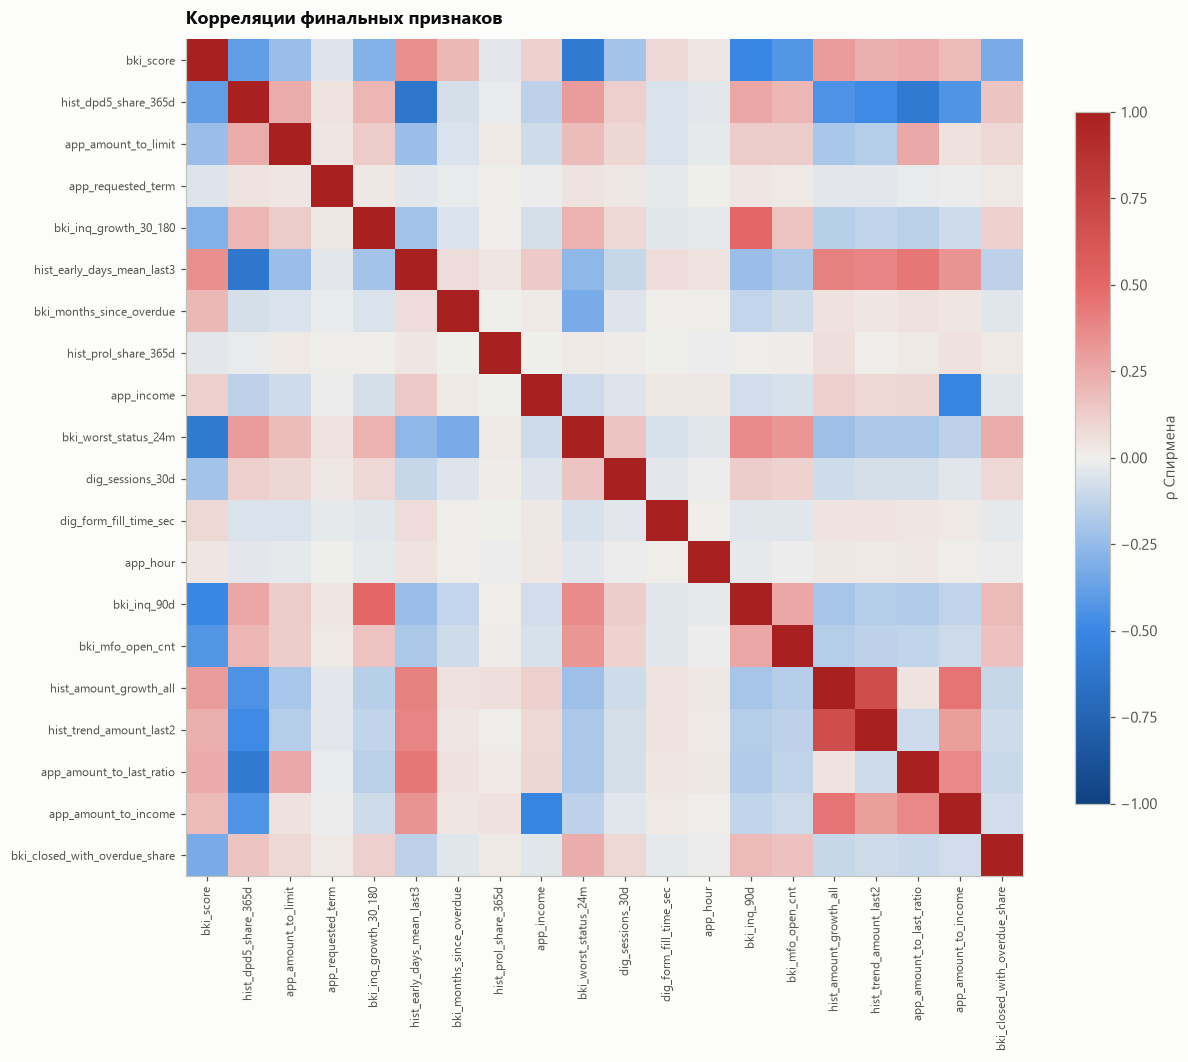

In [16]:
pl.saturation(T["saturation"], len(SELECTED), FIG)
plt.show()
final = (pd.DataFrame({"feature": SELECTED}).merge(T["iv"], on="feature").merge(T["stability"], on="feature")
         .merge(T["ensemble"][["feature", "ensemble_score", "top_sources"]], on="feature"))
final.insert(1, "источник", final.feature.str.split("_").str[0].map(fe.GROUPS))
print(f"Финальный набор: {len(SELECTED)} признаков")
display(final)
pl.correlation_heatmap(train, SELECTED, FIG)
plt.show()

**WoE-бины** двух сильнейших признаков: деревом на train подобраны границы, доля дефолтов монотонно меняется по бинам. Эти же бины используются для IV и для классической скоркарты ниже.

In [17]:
for f in SELECTED[:2]:
    print(f)
    display(selres.binners[f].table(train[f], train[TARGET]))

bki_score


,bin,n,bad_rate,range,woe
0,-1,1672,0.1507,missing,0.0073
1,0,2613,0.4152,(-inf; 546.5],-1.3779
2,1,1999,0.2936,(546.5; 575.5],-0.8429
3,2,1548,0.2552,(575.5; 592.5],-0.6497
4,3,5188,0.1931,(592.5; 636.5],-0.2907
5,4,4697,0.1375,(636.5; 670.5],0.1152
6,5,4925,0.0979,(670.5; 706.5],0.5001
7,6,2662,0.0721,(706.5; 728.5],0.8320
8,7,7214,0.0408,(728.5; inf],1.4369


hist_dpd5_share_365d


,bin,n,bad_rate,range,woe
0,-1,26,0.7308,missing,-2.6759
1,0,17576,0.0827,(-inf; 0.2404],0.6860
2,1,2887,0.1244,(0.2404; 0.3542],0.2303
3,2,3897,0.1863,(0.3542; 0.5635],-0.2466
4,3,1818,0.2640,(0.5635; 0.775],-0.6959
5,4,6314,0.3006,(0.775; inf],-0.8761


## 5. XGBoost: подбор гиперпараметров

Две модели обучаются **одной и той же процедурой**, чтобы сравнение было честным:
- **XGB base** — отобранные табличные признаки;
- **XGB + GRU** — те же признаки + `gru_score`.

Optuna (TPE, 40 trials на модель) максимизирует
$$\text{penalized Gini} = \text{Gini}_{valid} - 0.5 \cdot \max(0,\ \text{Gini}_{train} - \text{Gini}_{valid} - 0.03).$$
Чистый valid Gini склоняет поиск к переобученным конфигурациям. Штраф за разрыв train−valid сверх 0.03 выбирает модели, которые стабильнее переносятся на OOT. Число деревьев определяет early stopping по valid.

На ~40 тыс. строк XGBoost почти не ускоряется от числа потоков. Поэтому trials идут параллельно: 4 trial по 2 потока. Из-за этого порядок trials, а значит и итоговые параметры, могут немного отличаться между запусками.

Optuna: 306 c


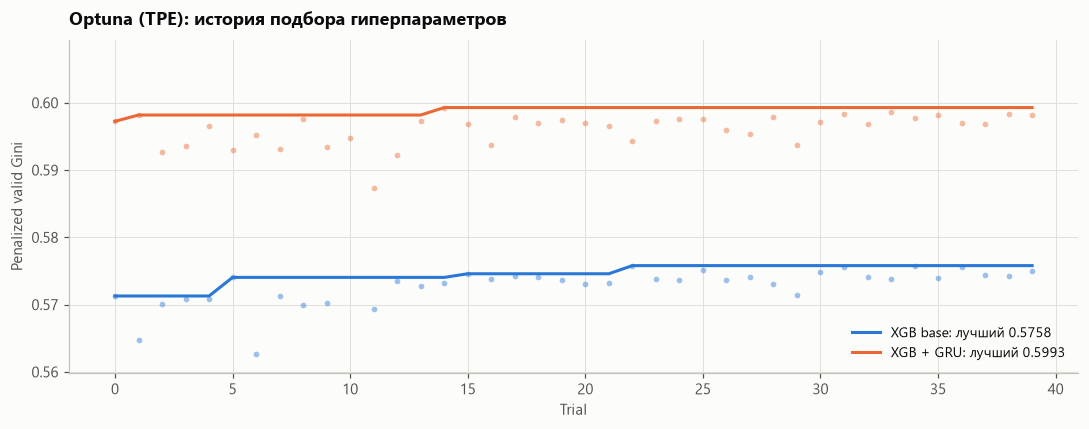

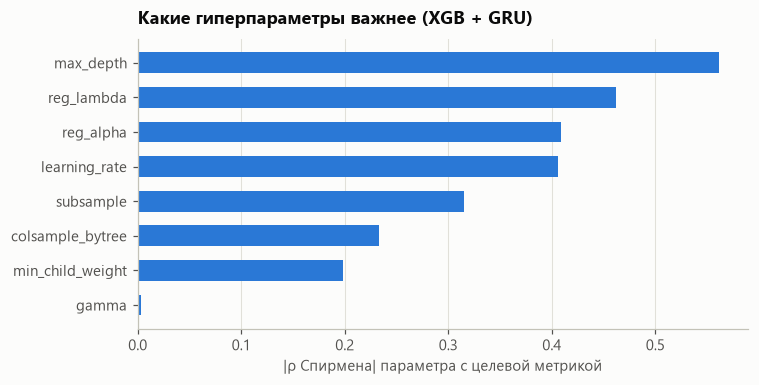

,XGB base,XGB + GRU
learning_rate,0.0459,0.0477
max_depth,4.0000,6.0000
min_child_weight,12.3630,11.4349
subsample,0.5621,0.6105
colsample_bytree,0.5215,0.5911
reg_alpha,0.0416,0.0304
reg_lambda,58.1245,76.0297
gamma,5.6059,4.8388
train_gini,0.5826,0.6116
valid_gini,0.5758,0.5993


In [18]:
STACK = SELECTED + ["gru_score"]
ytr, yva, yte = train[TARGET], valid[TARGET], test[TARGET]
t0 = time.time()
study_base = md.tune_xgb(train[SELECTED], ytr, valid[SELECTED], yva, n_trials=N_TRIALS, seed=SEED, n_jobs=N_JOBS)
study_stack = md.tune_xgb(train[STACK], ytr, valid[STACK], yva, n_trials=N_TRIALS, seed=SEED, n_jobs=N_JOBS)
print(f"Optuna: {time.time() - t0:.0f} c")
pl.optuna_history({"XGB base": study_base, "XGB + GRU": study_stack}, FIG)
plt.show()
pl.param_importance(study_stack, FIG)
plt.show()
best = pd.DataFrame({"XGB base": {**study_base.best_params, **study_base.best_trial.user_attrs},
                     "XGB + GRU": {**study_stack.best_params, **study_stack.best_trial.user_attrs}})
display(best)

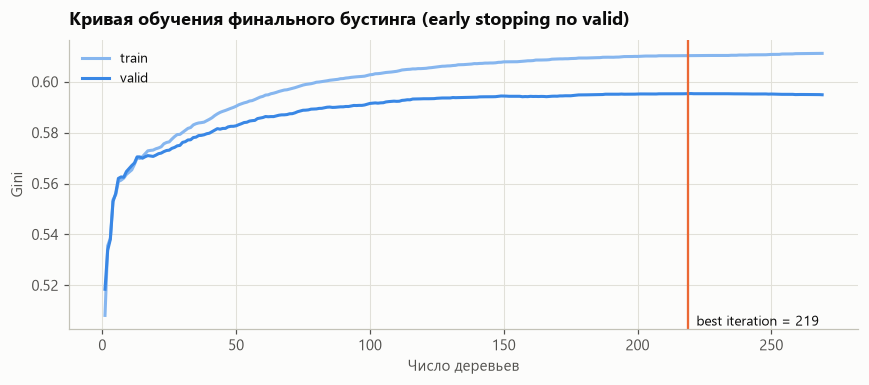

In [19]:
m_base = md.fit_final(study_base.best_params, train[SELECTED], ytr, valid[SELECTED], yva, seed=SEED, n_jobs=N_JOBS)
m_stack = md.fit_final(study_stack.best_params, train[STACK], ytr, valid[STACK], yva, seed=SEED, n_jobs=N_JOBS)
pl.boosting_curve(m_stack, FIG)
plt.show()

**Классический бейзлайн — WoE-скоркарта.** Те же отобранные признаки, бины дерева → WoE → логистическая регрессия → баллы (600 баллов при шансах 50:1, +20 баллов удваивают шансы). Скоркарта строится в двух вариантах: без GRU и с `gru_score` как ещё одним признаком. Так видно отдельно, сколько даёт новый источник информации и сколько — сложность модели. Если бустинг не обыгрывает скоркарту, его сложность не оправдана.

In [20]:
scorecard = md.WoeLogitScorecard(SELECTED).fit(train[SELECTED], ytr)
scorecard_gru = md.WoeLogitScorecard(STACK).fit(train[STACK], ytr)
points = scorecard.points_table(train[SELECTED], ytr)
display(points[points.feature.isin(SELECTED[:3])][["feature", "range", "n", "bad_rate", "woe", "points"]])

,feature,range,n,bad_rate,woe,points
0,bki_score,missing,1672,0.1507,0.0073,27.0000
1,bki_score,(-inf; 546.5],2613,0.4152,-1.3779,9.0000
2,bki_score,(546.5; 575.5],1999,0.2936,-0.8429,16.0000
3,bki_score,(575.5; 592.5],1548,0.2552,-0.6497,18.0000
4,bki_score,(592.5; 636.5],5188,0.1931,-0.2907,23.0000
5,bki_score,(636.5; 670.5],4697,0.1375,0.1152,28.0000
6,bki_score,(670.5; 706.5],4925,0.0979,0.5001,33.0000
7,bki_score,(706.5; 728.5],2662,0.0721,0.8320,38.0000
8,bki_score,(728.5; inf],7214,0.0408,1.4369,46.0000
9,hist_dpd5_share_365d,missing,26,0.7308,-2.6759,22.0000


## 6. Сравнение моделей на OOT

Доверительные интервалы считаются **бутстрэпом по клиентам** (500 повторов): клиенты ресэмплируются с возвращением, все их заявки идут вместе. Заявки одного клиента зависимы, и бутстрэп по строкам дал бы слишком узкие интервалы.

In [21]:
MODELS = {"WoE-логрег": "pd_scorecard", "XGB base": "pd_base", "GRU": "gru_score",
          "WoE-логрег + GRU": "pd_scorecard_gru", "XGB + GRU": "pd_stack"}
for part in (train, valid, test):
    part["pd_base"] = m_base.predict_proba(part[SELECTED])[:, 1]
    part["pd_stack"] = m_stack.predict_proba(part[STACK])[:, 1]
    part["pd_scorecard"] = scorecard.predict_proba(part[SELECTED])[:, 1]
    part["pd_scorecard_gru"] = scorecard_gru.predict_proba(part[STACK])[:, 1]
splits = {"train": train, "valid": valid, "oot": test}
results = pd.DataFrame({name: {s: mt.gini(p[TARGET], p[col]) for s, p in splits.items()} for name, col in MODELS.items()}).T
results["KS oot"] = [mt.ks(yte, test[c]) for c in MODELS.values()]
results["разрыв train−valid"] = results["train"] - results["valid"]
display(results)

,train,valid,oot,KS oot,разрыв train−valid
WoE-логрег,0.5611,0.5626,0.5225,0.3863,-0.0015
XGB base,0.5823,0.5761,0.5331,0.3987,0.0062
GRU,0.4737,0.4787,0.4669,0.3535,-0.0051
WoE-логрег + GRU,0.5867,0.5886,0.5486,0.4062,-0.0018
XGB + GRU,0.6103,0.5954,0.5560,0.4140,0.0149


Бутстрэп: 34 c


,metric,value,ci_low,ci_high,p_value
0,WoE-логрег,0.5225,0.5007,0.5426,NaN
1,XGB base,0.5331,0.5119,0.5523,NaN
2,GRU,0.4669,0.4452,0.4878,NaN
3,WoE-логрег + GRU,0.5486,0.5267,0.5687,NaN
4,XGB + GRU,0.5560,0.5349,0.5764,NaN
5,Δ XGB + GRU − XGB base,0.0229,0.0176,0.0288,0.0000
6,Δ XGB + GRU − WoE-логрег + GRU,0.0074,0.0026,0.0120,0.0020
7,Δ XGB base − WoE-логрег,0.0106,0.0058,0.0150,0.0000
8,Δ WoE-логрег + GRU − WoE-логрег,0.0261,0.0197,0.0333,0.0000
9,Δ XGB + GRU − GRU,0.0892,0.0774,0.1019,0.0000


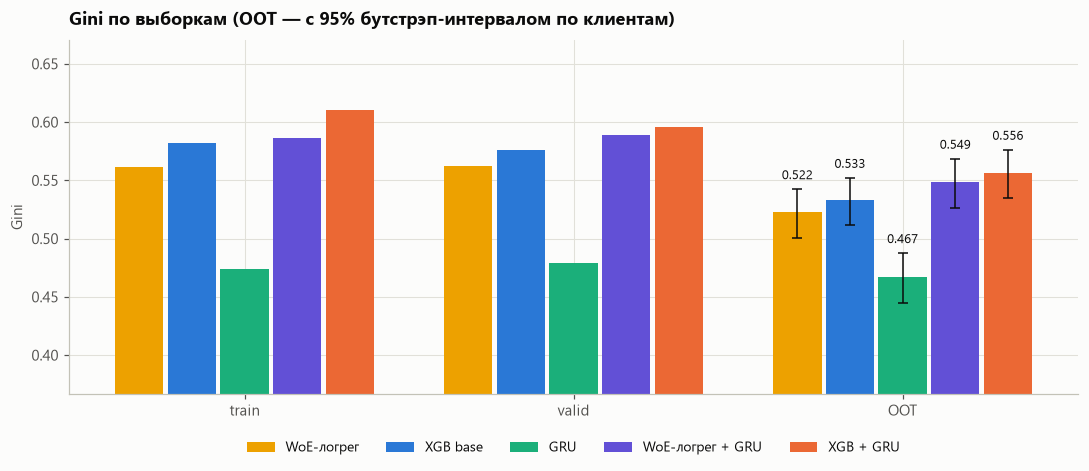

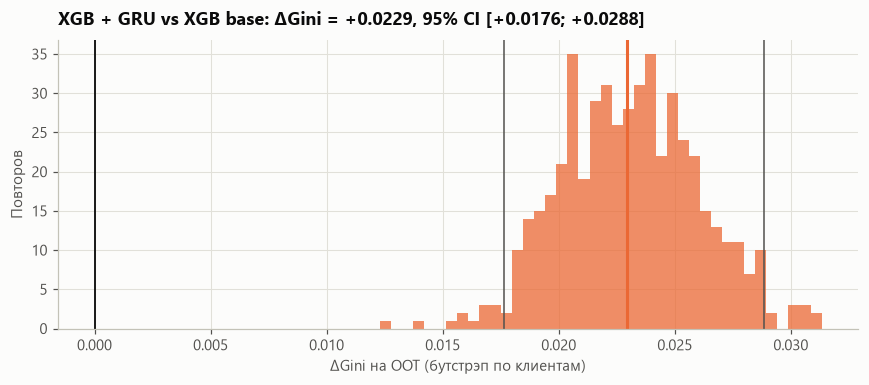

In [22]:
t0 = time.time()
boot = md.bootstrap_gini(yte, {k: test[v] for k, v in MODELS.items()}, test.client_id, n_boot=500, seed=SEED)
point = {k: mt.gini(yte, test[v]) for k, v in MODELS.items()}
summary = md.summarize_bootstrap(boot, point, [("XGB + GRU", "XGB base"), ("XGB + GRU", "WoE-логрег + GRU"),
                                               ("XGB base", "WoE-логрег"), ("WoE-логрег + GRU", "WoE-логрег"), ("XGB + GRU", "GRU")])
print(f"Бутстрэп: {time.time() - t0:.0f} c")
display(summary)
ci = summary.set_index("metric").loc[list(MODELS), ["ci_low", "ci_high"]]
pl.gini_comparison(results[["train", "valid", "oot"]], ci, FIG)
plt.show()
d_uplift = (boot["XGB + GRU"] - boot["XGB base"]).to_numpy()
pl.delta_bootstrap(d_uplift, point["XGB + GRU"] - point["XGB base"], "XGB + GRU vs XGB base", FIG)
plt.show()

,заявок,bad rate,WoE-логрег,XGB base,GRU,WoE-логрег + GRU,XGB + GRU,Δ stack−base,CI low,CI high
segment,,,,,,,,,,
L2,5905,0.1865,0.4646,0.4739,0.3849,0.4988,0.5072,0.0333,0.0230,0.0446
L3,3819,0.1767,0.5183,0.5318,0.4595,0.5479,0.5518,0.0200,0.0086,0.0314
L4+,7059,0.1547,0.5725,0.5814,0.5313,0.5894,0.5966,0.0152,0.0070,0.0243


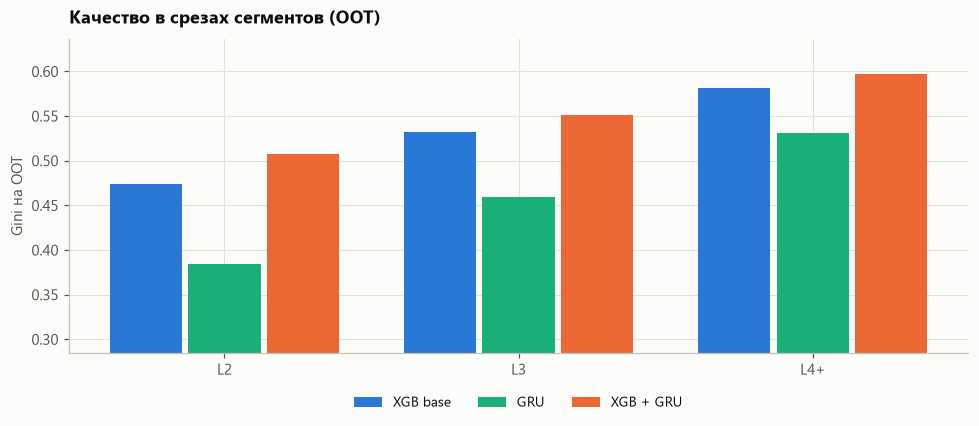

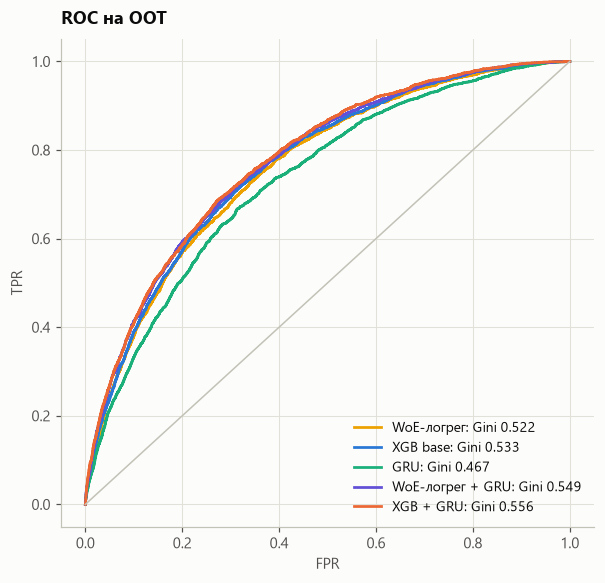

In [23]:
seg_rows = []
for seg, g in test.groupby("segment"):
    b = md.bootstrap_gini(g[TARGET], {"base": g.pd_base, "stack": g.pd_stack}, g.client_id, n_boot=300, seed=SEED)
    d = b["stack"] - b["base"]
    seg_rows.append({"segment": seg, "заявок": len(g), "bad rate": g[TARGET].mean(),
                     **{name: mt.gini(g[TARGET], g[col]) for name, col in MODELS.items()},
                     "Δ stack−base": mt.gini(g[TARGET], g.pd_stack) - mt.gini(g[TARGET], g.pd_base),
                     "CI low": d.quantile(0.025), "CI high": d.quantile(0.975)})
by_segment = pd.DataFrame(seg_rows).set_index("segment")
display(by_segment)
pl.gini_by_segment(by_segment[["XGB base", "GRU", "XGB + GRU"]], FIG)
plt.show()
pl.roc_curves({name: (yte, test[col]) for name, col in MODELS.items()}, FIG)
plt.show()

## 7. Интерпретация: SHAP

SHAP-значения считает сам XGBoost (`pred_contribs=True`): это точный TreeSHAP без отдельной библиотеки. Выборка — 4 000 заявок OOT.

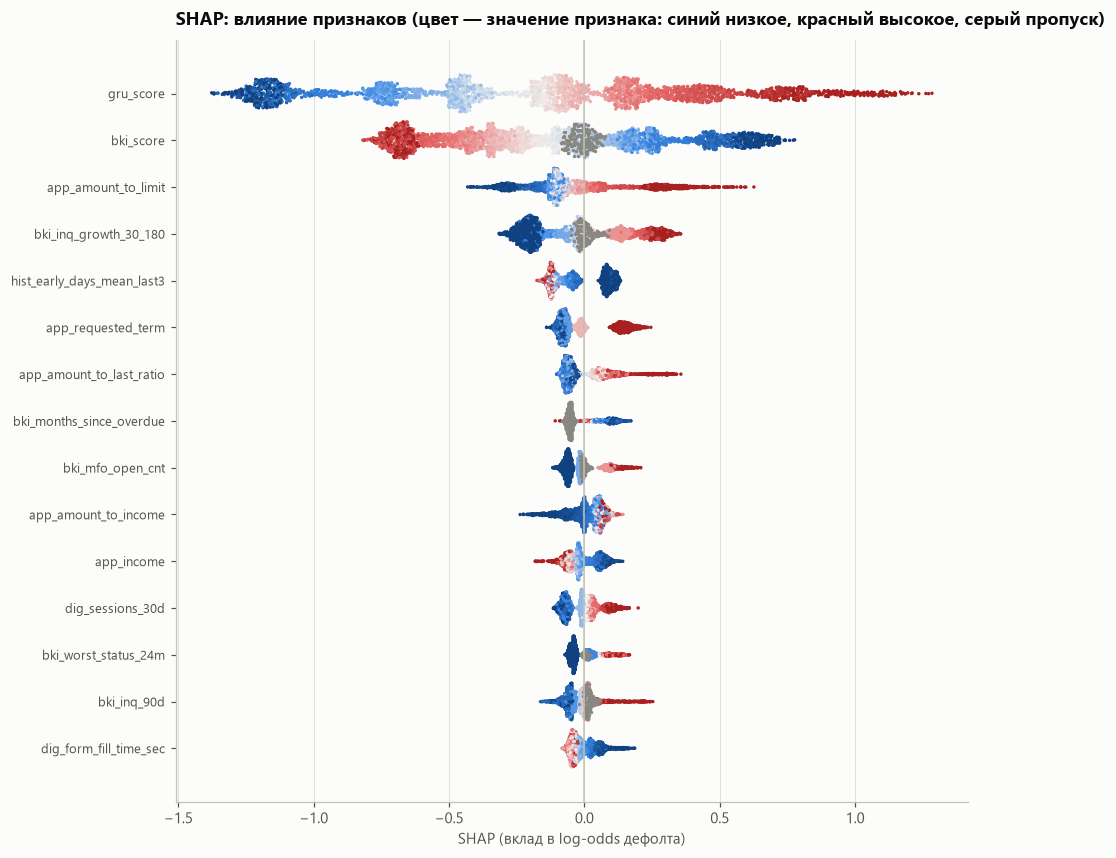

,mean |SHAP|
gru_score,0.5409
bki_score,0.3633
app_amount_to_limit,0.1531
bki_inq_growth_30_180,0.1505
hist_early_days_mean_last3,0.0918
app_requested_term,0.0868
app_amount_to_last_ratio,0.0747
bki_months_since_overdue,0.0650
bki_mfo_open_cnt,0.0545
app_amount_to_income,0.0514


In [24]:
xs = test[STACK].sample(4000, random_state=SEED)
contrib = m_stack.get_booster().predict(xgb.DMatrix(xs), pred_contribs=True, iteration_range=(0, m_stack.best_iteration + 1))
shap_values = contrib[:, :-1]
shap_imp = pd.Series(np.abs(shap_values).mean(0), index=STACK).sort_values(ascending=False)
pl.shap_beeswarm(shap_values, xs, top=15, out_dir=FIG)
plt.show()
display(shap_imp.head(10).to_frame("mean |SHAP|"))

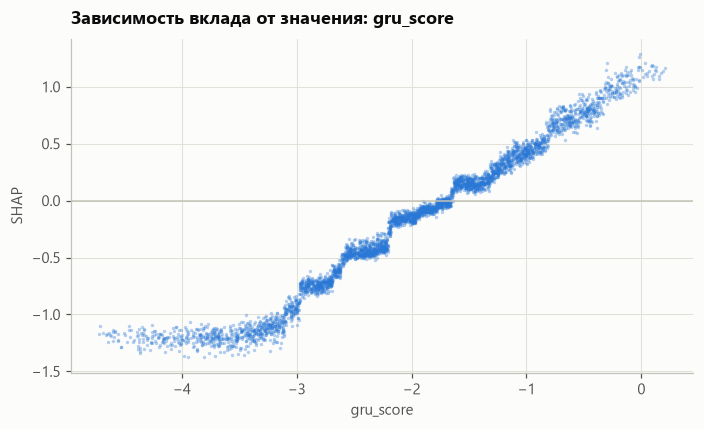

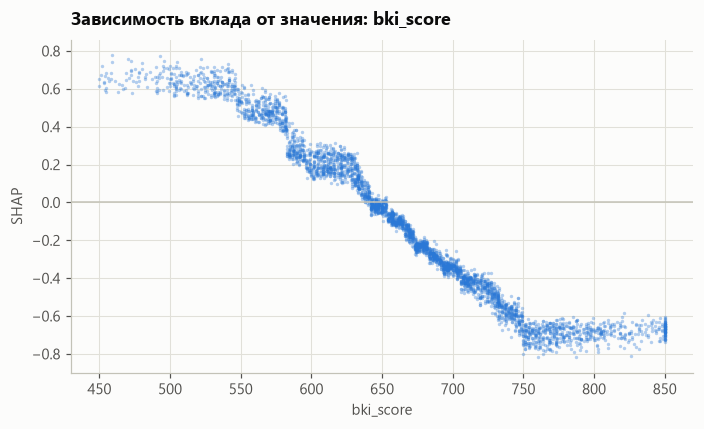

In [25]:
pl.shap_dependence(xs["gru_score"].to_numpy(), shap_values[:, STACK.index("gru_score")], "gru_score", FIG, "61_shap_dependence_gru_score")
plt.show()
top_tab = next(f for f in shap_imp.index if f != "gru_score")
pl.shap_dependence(xs[top_tab].to_numpy(), shap_values[:, STACK.index(top_tab)], top_tab, FIG, "62_shap_dependence_top_feature")
plt.show()

## 8. Стабильность и калибровка

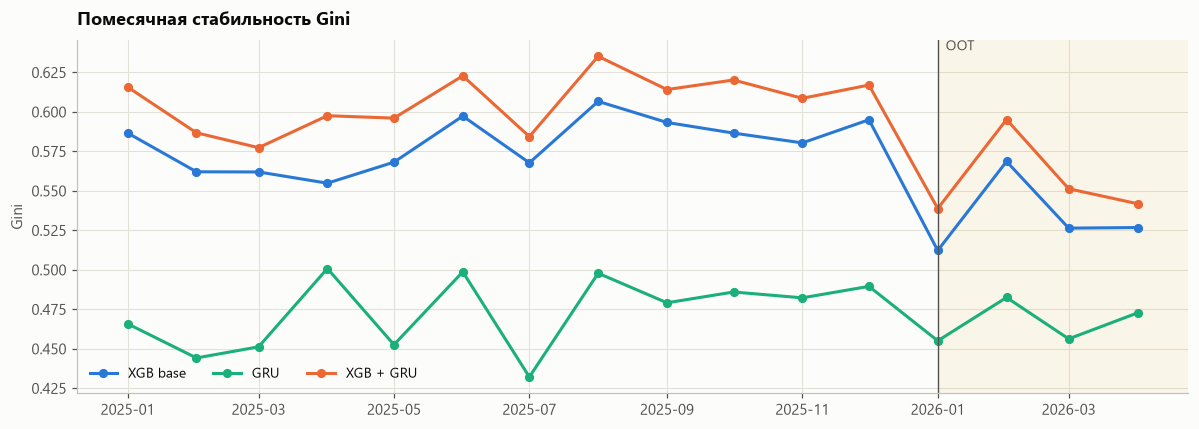

,PSI скора train → OOT
WoE-логрег,0.0017
XGB base,0.0015
GRU,0.0016
WoE-логрег + GRU,0.0003
XGB + GRU,0.0005


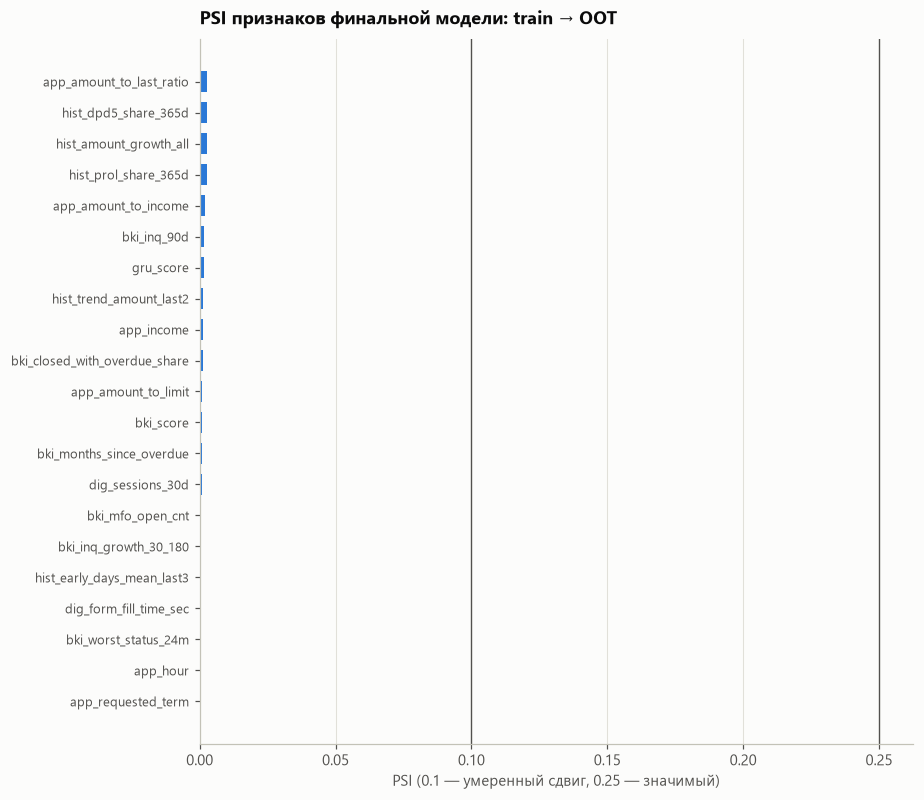

In [26]:
allp = pd.concat([train, valid, test], ignore_index=True)
allp["month"] = allp.application_date.dt.to_period("M").dt.to_timestamp()
monthly = mt.gini_by_period(allp, "month", TARGET, list(MODELS.values())).rename(columns={v: k for k, v in MODELS.items()})
pl.monthly_gini(monthly, ["XGB base", "GRU", "XGB + GRU"], OOT_START, FIG)
plt.show()
score_psi = pd.Series({name: mt.psi(train[col], test[col]) for name, col in MODELS.items()}, name="PSI скора train → OOT")
display(score_psi.to_frame())
feat_psi = pd.Series({f: mt.psi(train[f], test[f]) for f in STACK})
pl.psi_bars(feat_psi, FIG)
plt.show()

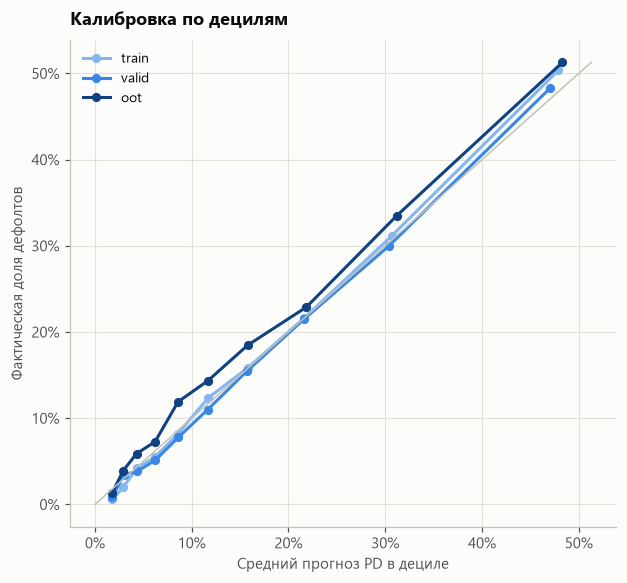

,train,valid,oot
средний PD,0.1515,0.1504,0.1527
факт NPL30d90,0.1518,0.1473,0.1709


In [27]:
calib = {s: mt.calibration_table(p[TARGET], p["pd_stack"]) for s, p in splits.items()}
pl.calibration(calib, FIG)
plt.show()
display(pd.DataFrame({s: {"средний PD": p.pd_stack.mean(), "факт NPL30d90": p[TARGET].mean()} for s, p in splits.items()}))

Ранжирование на OOT держится, а уровень дефолта вырос (макросдвиг). Поэтому PD систематически ниже факта. Для внедрения это решается **перекалибровкой** на свежем окне без переобучения модели: сдвигом intercept в логит-шкале или изотонической регрессией. Риск-грейды строятся по квантилям PD на train и должны оставаться монотонными на всех выборках.

,grade,loans,avg_pd,min_pd,max_pd,bad_rate,bads,share,cum_share,cum_bad_rate,cum_bad_capture
0,1,1648,0.0180,0.0116,0.0235,0.0133,22,0.0982,0.0982,0.0133,1.0000
1,2,1731,0.0292,0.0235,0.0356,0.0399,69,0.1031,0.2013,0.0269,0.9923
2,3,1643,0.0431,0.0356,0.0518,0.0590,97,0.0979,0.2992,0.0374,0.9683
3,4,1691,0.0620,0.0518,0.0730,0.0721,122,0.1008,0.4000,0.0462,0.9344
4,5,1657,0.0858,0.0731,0.0999,0.1201,199,0.0987,0.4987,0.0608,0.8919
5,6,1695,0.1166,0.0999,0.1355,0.1410,239,0.1010,0.5997,0.0743,0.8225
6,7,1679,0.1577,0.1355,0.1837,0.1852,311,0.1000,0.6998,0.0902,0.7392
7,8,1607,0.2165,0.1838,0.2540,0.2259,363,0.0958,0.7955,0.1065,0.6308
8,9,1705,0.3077,0.2541,0.3701,0.3331,568,0.1016,0.8971,0.1322,0.5042
9,10,1727,0.4800,0.3702,0.7288,0.5084,878,0.1029,1.0000,0.1709,0.3061


Строгая монотонность bad rate по грейдам: {'train': True, 'valid': True, 'oot': True}


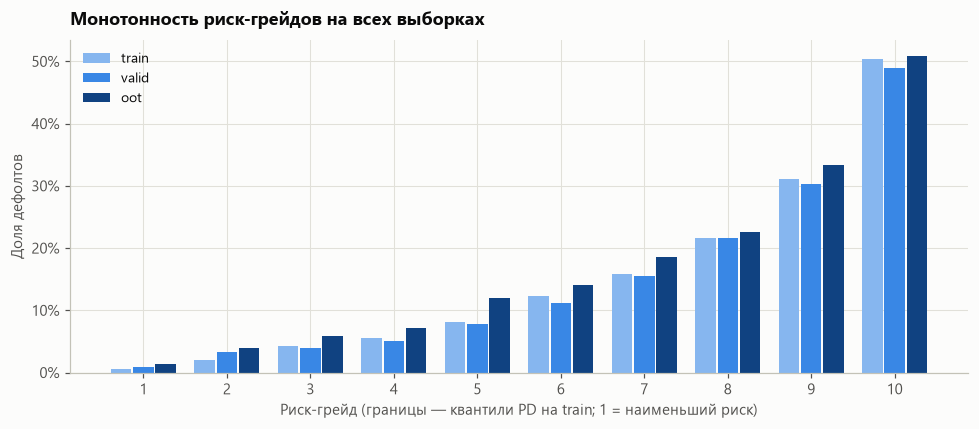

In [28]:
edges = mt.fit_grade_edges(train.pd_stack, 10)
grades = {s: mt.risk_grade_table(p[TARGET].to_numpy(), p.pd_stack.to_numpy(), mt.apply_grade_edges(p.pd_stack, edges))
          for s, p in splits.items()}
display(grades["oot"])
monotone = {s: bool(np.all(np.diff(t.bad_rate.to_numpy()) > 0)) for s, t in grades.items()}
print("Строгая монотонность bad rate по грейдам:", monotone)
pl.risk_grades(grades, FIG)
plt.show()

## 9. Бизнес-эффект: стратегическая кривая

Заявки одобряются в порядке возрастания PD. Для каждого уровня одобрения смотрим долю дефолтов среди одобренных. Чем ниже кривая, тем меньше потерь при том же объёме выдач.

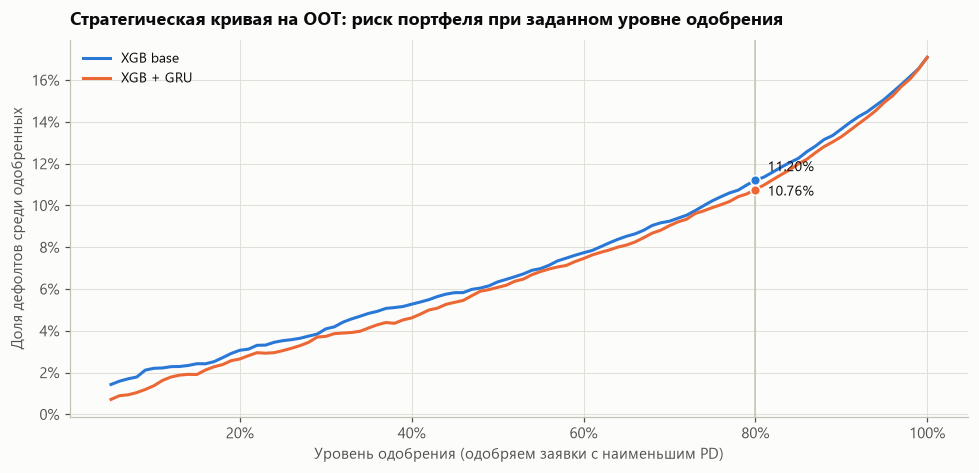

,уровень одобрения,bad rate: XGB base,bad rate: XGB + GRU,"снижение, отн."
0,0.6000,0.0774,0.0746,0.0359
1,0.7000,0.0924,0.0903,0.0230
2,0.8000,0.1120,0.1076,0.0392
3,0.9000,0.1366,0.1329,0.0271


При риске портфеля 11.20% (база при 80% одобрения) модель с GRU одобряет 81% заявок


In [29]:
curves = {name: mt.approval_curve(yte, test[MODELS[name]]) for name in ["XGB base", "XGB + GRU"]}
pl.approval_curves(curves, at=0.8, out_dir=FIG)
plt.show()
rows = []
for ar in [0.6, 0.7, 0.8, 0.9]:
    b = np.interp(ar, curves["XGB base"].approval_rate, curves["XGB base"].bad_rate)
    s = np.interp(ar, curves["XGB + GRU"].approval_rate, curves["XGB + GRU"].bad_rate)
    rows.append({"уровень одобрения": ar, "bad rate: XGB base": b, "bad rate: XGB + GRU": s, "снижение, отн.": 1 - s / b})
business = pd.DataFrame(rows)
display(business)
# тот же риск портфеля, что у базовой модели при 80% одобрения: насколько больше можно одобрить
target_br = np.interp(0.8, curves["XGB base"].approval_rate, curves["XGB base"].bad_rate)
c = curves["XGB + GRU"]
ar_same_risk = float(c.loc[c.bad_rate <= target_br, "approval_rate"].max())
print(f"При риске портфеля {target_br:.2%} (база при 80% одобрения) модель с GRU одобряет {ar_same_risk:.0%} заявок")

## 10. Готовность к внедрению

- **GRU без torch.** Веса четырёх фолдов выгружаются в numpy, прямой проход переписан по формулам `torch.nn.GRU`. В проде не нужен torch, а скоринг одной заявки — это цикл по ≤128 токенам. Паритет проверяется на заявках OOT.
- **Артефакты**: бустинги (JSON-формат XGBoost), веса GRU, статистики стандартизации токенов, список признаков, гиперпараметры и метрики в `model_card.json`.

In [30]:
scorer = G.GruNumpyScorer(oof.models, GRU_CFG.max_len)
ix = np.flatnonzero(df.split.eq("oot").to_numpy())[:300]
xb, L = G.make_batch(ix, store, GRU_CFG.max_len)
np_logit = np.array([scorer.logit(xb[i, :L[i]].numpy(), seg_idx[ix[i]]) for i in range(len(ix))])
parity = float(np.abs(np_logit - df.gru_score.to_numpy()[ix]).max())
print(f"max |logit numpy − logit torch| на {len(ix)} заявках OOT: {parity:.1e}")
assert parity < 1e-4

max |logit numpy − logit torch| на 300 заявках OOT: 4.7e-07


In [31]:
ARTEFACTS_DIR.mkdir(parents=True, exist_ok=True)
m_base.save_model(ARTEFACTS_DIR / "xgb_base.json")
m_stack.save_model(ARTEFACTS_DIR / "xgb_stack.json")
torch.save([m.state_dict() for m in oof.models], ARTEFACTS_DIR / "gru_folds.pt")
np.save(ARTEFACTS_DIR / "token_mu_sd.npy", np.stack([store.mu, store.sd]))
card = {
    "target": TARGET, "oot_start": str(OOT_START.date()),
    "selected_features": SELECTED, "stack_features": STACK, "token_fields": store.fields,
    "gru_config": oof.config, "xgb_base_params": study_base.best_params, "xgb_stack_params": study_stack.best_params,
    "gini": results[["train", "valid", "oot"]].round(4).to_dict(orient="index"),
    "oot_delta_stack_vs_base": summary.set_index("metric").loc["Δ XGB + GRU − XGB base", ["value", "ci_low", "ci_high"]].round(4).to_dict(),
    "gru_numpy_parity": parity,
}
(ARTEFACTS_DIR / "model_card.json").write_text(json.dumps(card, ensure_ascii=False, indent=2), encoding="utf-8")
print("Сохранено:", sorted(p.name for p in ARTEFACTS_DIR.iterdir()))

Сохранено: ['gru_folds.pt', 'model_card.json', 'token_mu_sd.npy', 'xgb_base.json', 'xgb_stack.json']


## 11. Выводы

In [32]:
d = summary.set_index("metric")
up = d.loc["Δ XGB + GRU − XGB base"]


def delta_txt(key, better, same):
    r = d.loc[key]
    ci = f"Δ {r['value']:+.3f}, 95% CI [{r['ci_low']:+.3f}; {r['ci_high']:+.3f}]"
    return f"{better} ({ci})" if r["ci_low"] > 0 else f"{same} ({ci})"


woe_txt = delta_txt("Δ XGB base − WoE-логрег", "без GRU бустинг значимо лучше WoE-скоркарты на тех же признаках",
                    "без GRU бустинг сопоставим с WoE-скоркартой на тех же признаках")
woe_gru_txt = delta_txt("Δ XGB + GRU − WoE-логрег + GRU", "с GRU бустинг значимо лучше скоркарты с тем же `gru_score`",
                        "с GRU бустинг сопоставим со скоркартой с тем же `gru_score`")
gain_lr = d.loc["Δ WoE-логрег + GRU − WoE-логрег", "value"]
seg_txt = ", ".join(f"{s} {r['Δ stack−base']:+.3f}" for s, r in by_segment.iterrows())
br80 = business.set_index("уровень одобрения").loc[0.8]
display(Markdown(f'''
1. **GRU как реконструкция признака работает.** Одиночный `gru_score` даёт Gini {point["GRU"]:.3f} на OOT, используя только сырую историю событий.
   В стеке с табличными признаками прирост к бустингу без GRU составляет **{up["value"]:+.3f} Gini** на OOT
   (95% CI [{up["ci_low"]:+.3f}; {up["ci_high"]:+.3f}], бутстрэп по клиентам), по сегментам: {seg_txt}.
   GRU извлекает то, чего нет в агрегатах: микродинамику внутри займа, то есть насколько близко к дедлайну и каким путём клиент гасит обязательства.
2. **Отбор признаков** сократил {len(FEATURES)} кандидатов до {len(SELECTED)}. По пути он отсеял утечку (`coll_calls_cnt_90d`), дрейфующие поля (смена шкалы бюро, версия приложения, новый канал), пустые и константные поля, шум и дубли. Кривая насыщения показала, что больше признаков качества не добавляют.
3. **XGBoost с penalized-Gini-тюнингом**: итоговый Gini train / valid / OOT = {results.loc["XGB + GRU", "train"]:.3f} / {results.loc["XGB + GRU", "valid"]:.3f} / {results.loc["XGB + GRU", "oot"]:.3f}.
   Сравнение со скоркартой разделяет вклад источника информации и вклад сложности модели. Источник: `gru_score` добавляет скоркарте {gain_lr:+.3f} Gini. Сложность модели: {woe_txt}; {woe_gru_txt}.
   Риск-грейды монотонны на всех выборках, PSI скора train → OOT = {score_psi["XGB + GRU"]:.3f}.
4. **Бизнес-эффект**: при 80% одобрения доля дефолтов среди одобренных снижается с {br80["bad rate: XGB base"]:.2%} до {br80["bad rate: XGB + GRU"]:.2%}
   ({br80["снижение, отн."]:.1%} отн.). При том же риске портфеля можно одобрять {ar_same_risk:.0%} заявок вместо 80%.
5. **Ограничения и что дальше**: уровень PD в OOT ниже факта из-за макросдвига, перед внедрением нужна перекалибровка.
   GRU можно обогащать новыми типами событий (заявки, отказы, коммуникации) без ручного feature engineering, достаточно добавить флаг в токен.
'''))
print(f"Время выполнения ноутбука: {(time.time() - T_START) / 60:.1f} мин")


1. **GRU как реконструкция признака работает.** Одиночный `gru_score` даёт Gini 0.467 на OOT, используя только сырую историю событий.
   В стеке с табличными признаками прирост к бустингу без GRU составляет **+0.023 Gini** на OOT
   (95% CI [+0.018; +0.029], бутстрэп по клиентам), по сегментам: L2 +0.033, L3 +0.020, L4+ +0.015.
   GRU извлекает то, чего нет в агрегатах: микродинамику внутри займа, то есть насколько близко к дедлайну и каким путём клиент гасит обязательства.
2. **Отбор признаков** сократил 304 кандидатов до 20. По пути он отсеял утечку (`coll_calls_cnt_90d`), дрейфующие поля (смена шкалы бюро, версия приложения, новый канал), пустые и константные поля, шум и дубли. Кривая насыщения показала, что больше признаков качества не добавляют.
3. **XGBoost с penalized-Gini-тюнингом**: итоговый Gini train / valid / OOT = 0.610 / 0.595 / 0.556.
   Сравнение со скоркартой разделяет вклад источника информации и вклад сложности модели. Источник: `gru_score` добавляет скоркарте +0.026 Gini. Сложность модели: без GRU бустинг значимо лучше WoE-скоркарты на тех же признаках (Δ +0.011, 95% CI [+0.006; +0.015]); с GRU бустинг значимо лучше скоркарты с тем же `gru_score` (Δ +0.007, 95% CI [+0.003; +0.012]).
   Риск-грейды монотонны на всех выборках, PSI скора train → OOT = 0.000.
4. **Бизнес-эффект**: при 80% одобрения доля дефолтов среди одобренных снижается с 11.20% до 10.76%
   (3.9% отн.). При том же риске портфеля можно одобрять 81% заявок вместо 80%.
5. **Ограничения и что дальше**: уровень PD в OOT ниже факта из-за макросдвига, перед внедрением нужна перекалибровка.
   GRU можно обогащать новыми типами событий (заявки, отказы, коммуникации) без ручного feature engineering, достаточно добавить флаг в токен.


Время выполнения ноутбука: 14.2 мин
